# Customer Segmentation Analysis Using K-Means Clustering

## Project Objective

This notebook segments customers from the supplied **Online Retail** transaction dataset using Recency, Frequency, and Monetary (RFM) behaviour features and K-Means clustering. The analysis is designed for a university-level business analytics submission: every cleaning decision is documented, the source workbook is preserved unchanged, and conclusions are based only on observed customer behaviour.

The notebook follows the required order:

1. Project Title and Objective  
2. Import Libraries  
3. Load Dataset  
4. Dataset Inspection  
5. Data Cleaning  
6. Exploratory Data Analysis  
7. Descriptive Statistics  
8. RFM Analysis  
9. Feature Selection  
10. Data Standardisation  
11. Elbow Method  
12. K-Means Clustering  
13. Cluster Scatter Plots  
14. Cluster Profiling  
15. Customer Count Bar Chart  
16. Business Insights and Marketing Recommendations  
17. Final Conclusion

Source file: Online Retail.xlsx
Loaded shape: (541909, 8)

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


Rows: 541,909 | Columns: 8

Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str



Missing values:


,missing_count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Duplicate records: 5,268


Cleaning checks before filtering:


,count
Original rows,541909
Duplicate rows,5268
Cancelled invoices,9288
Nonpositive quantities,10624
Nonpositive unit prices,2517
Invalid dates,0
Missing customer IDs,135080


Rows after cleaning: 392,692
Rows removed: 149,217
Remaining invalid values:


,missing_count
InvoiceDate,0
Quantity,0
UnitPrice,0
CustomerID,0
PurchaseAmount,0


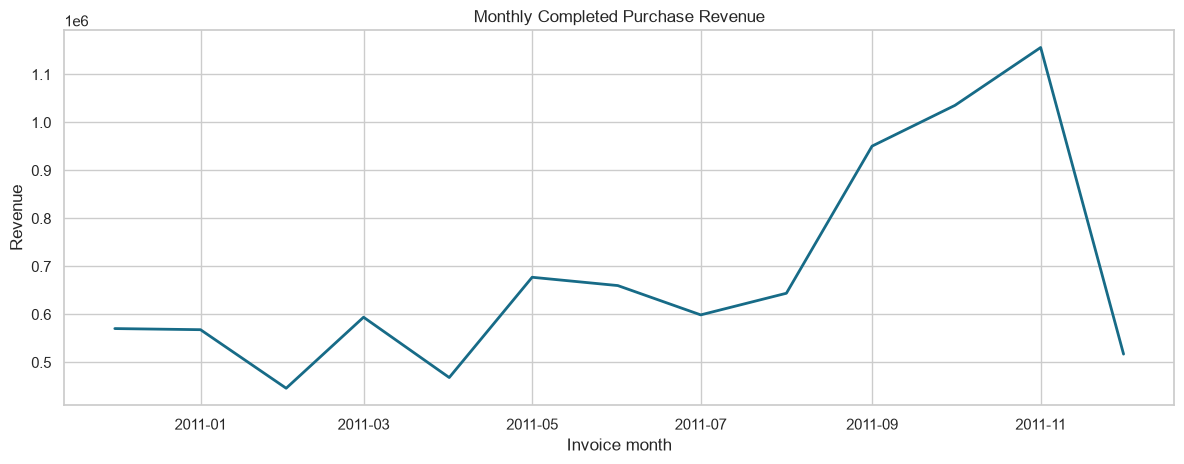

,Metric,Definition,Overall average
0,Average Purchase Value,"Mean completed invoice value per customer, ave...",417.65
1,Purchase Frequency,Number of unique completed invoices per customer.,4.27
2,Customer Lifetime Value,Observed historical customer revenue: average ...,"2,048.69"


Reference date for Recency: 2011-12-09 12:50:00
Recency = days since last purchase; Frequency = completed invoice count; Monetary = completed revenue.


,CustomerID,Recency,Frequency,Monetary
0,12346,325,1,"77,183.60"
1,12347,1,7,"4,310.00"
2,12348,74,4,"1,797.24"
3,12349,18,1,"1,757.55"
4,12350,309,1,334.40


Features selected for clustering: ['Recency', 'Frequency', 'Monetary']
Customers available for clustering: 4,338
Scaled feature preview:


,Recency,Frequency,Monetary
0,2.33,-0.43,8.36
1,-0.91,0.35,0.25
2,-0.18,-0.04,-0.03
3,-0.74,-0.43,-0.03
4,2.17,-0.43,-0.19


Scaled means: {'Recency': 0.0, 'Frequency': 0.0, 'Monetary': 0.0}


,K,WCSS_Inertia
0,1,"13,014.00"
1,2,"9,014.57"
2,3,"5,441.32"
3,4,"4,096.30"
4,5,"3,119.79"
5,6,"2,473.79"
6,7,"2,023.59"
7,8,"1,717.01"
8,9,"1,468.79"
9,10,"1,281.05"


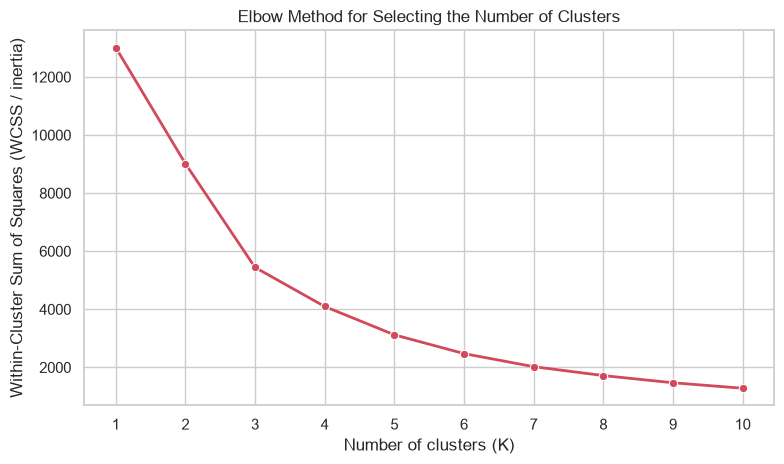

Selected K: 4. The elbow is used as the practical compactness-versus-interpretability trade-off.
Cluster assignment counts:


,Customer_Count
Cluster,
0,3054
1,1067
2,13
3,204


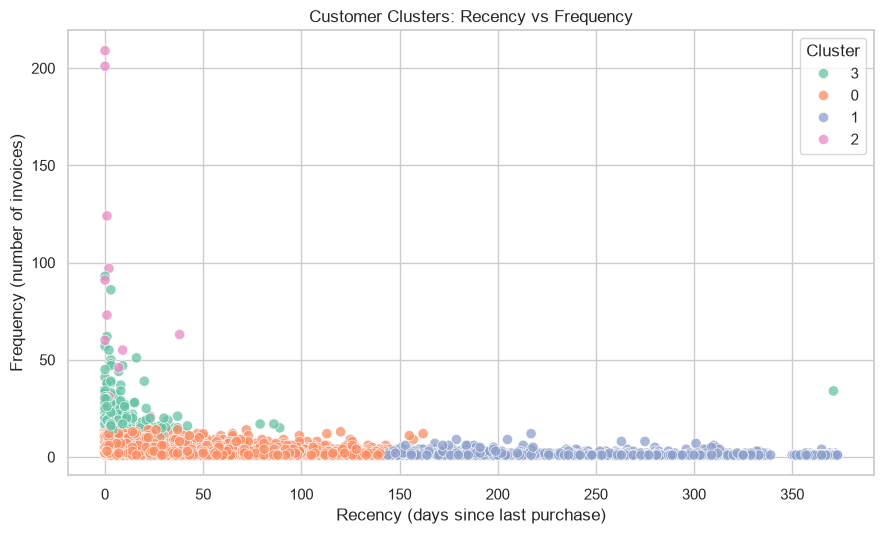

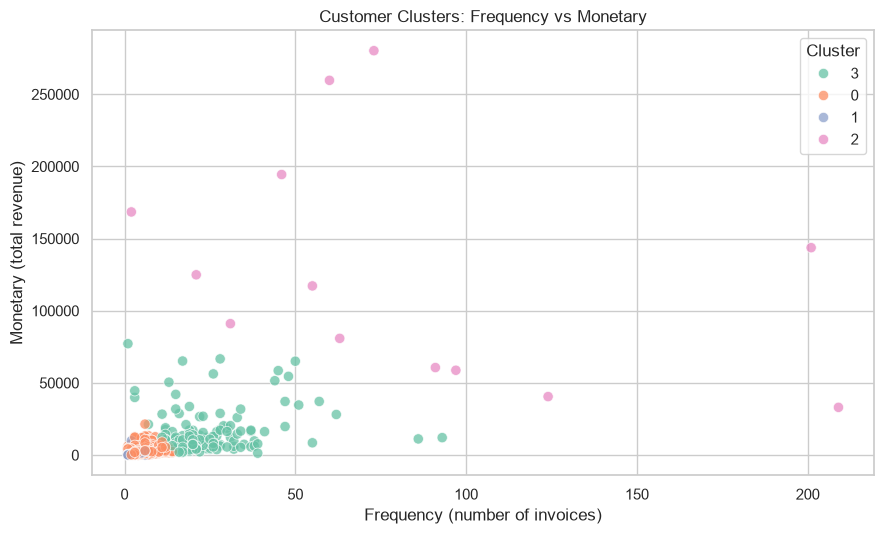

,Cluster,Recency,Frequency,Monetary,Customer_Count,Customer_Type,Marketing_Action
0,0,42.70,3.68,"1,353.63",3054,Hibernating / Low-Engagement Customers,Test targeted reactivation discounts while con...
1,1,247.08,1.55,478.85,1067,Hibernating / Low-Engagement Customers,Test targeted reactivation discounts while con...
2,2,6.38,82.54,"127,187.96",13,Champions / Loyal Customers,"Protect loyalty with rewards, early access, an..."
3,3,14.50,22.33,"12,690.50",204,Champions / Loyal Customers,"Protect loyalty with rewards, early access, an..."


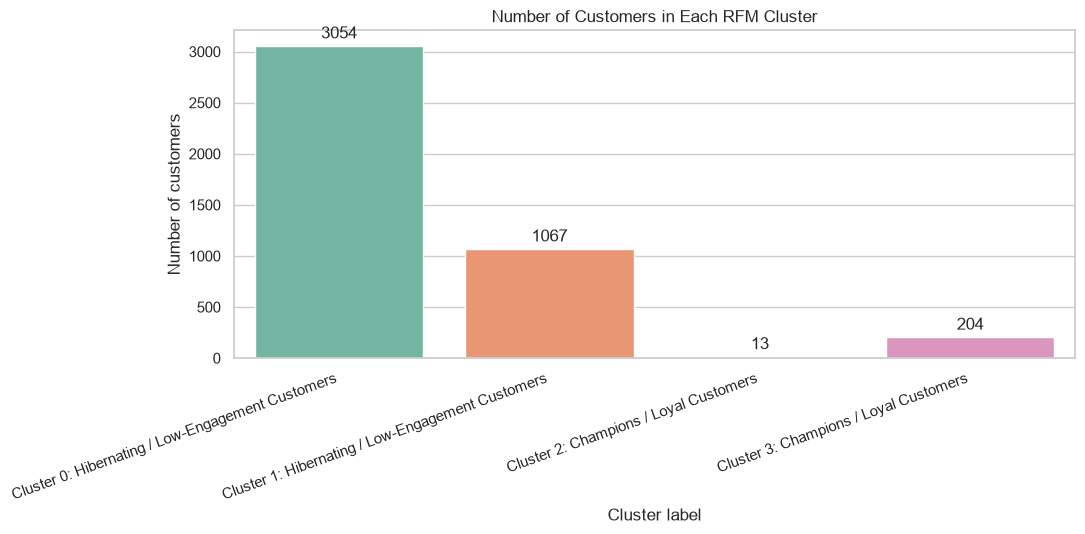

Business insights and marketing recommendations

Cluster 0: Hibernating / Low-Engagement Customers
Average recency: 42.7 days | Average frequency: 3.7 invoices | Average monetary value: $1,353.63
Recommendation: Test targeted reactivation discounts while controlling promotion cost.

Cluster 1: Hibernating / Low-Engagement Customers
Average recency: 247.1 days | Average frequency: 1.6 invoices | Average monetary value: $478.85
Recommendation: Test targeted reactivation discounts while controlling promotion cost.

Cluster 2: Champions / Loyal Customers
Average recency: 6.4 days | Average frequency: 82.5 invoices | Average monetary value: $127,187.96
Recommendation: Protect loyalty with rewards, early access, and cross-sell offers.

Cluster 3: Champions / Loyal Customers
Average recency: 14.5 days | Average frequency: 22.3 invoices | Average monetary value: $12,690.50
Recommendation: Protect loyalty with rewards, early access, and cross-sell offers.
Saved report to /Users/atifnawaz/Retail

In [1]:
# 2. Import Libraries
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

# 3. Load Dataset
source_path = Path('/Users/atifnawaz/Downloads/Online Retail.xlsx')
if not source_path.exists():
    raise FileNotFoundError(f'Source dataset not found: {source_path}')
raw_dataset = pd.read_excel(source_path, sheet_name=0)
working_dataset = raw_dataset.copy(deep=True)
print(f'Source file: {source_path.name}')
print(f'Loaded shape: {raw_dataset.shape}')

# 4. Dataset Inspection
print('\nFirst five rows:')
display(raw_dataset.head())
print(f'Rows: {raw_dataset.shape[0]:,} | Columns: {raw_dataset.shape[1]}')
print('\nColumn names:', raw_dataset.columns.tolist())
print('\nData types:')
display(raw_dataset.dtypes.to_frame('dtype'))
print('\nMissing values:')
display(raw_dataset.isna().sum().to_frame('missing_count'))
print(f'Duplicate records: {raw_dataset.duplicated().sum():,}')

# 5. Data Cleaning
required_columns = {'InvoiceNo', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID'}
missing_required = required_columns.difference(working_dataset.columns)
if missing_required:
    raise ValueError(f'Missing required columns for RFM analysis: {sorted(missing_required)}')
working_dataset['InvoiceNo'] = working_dataset['InvoiceNo'].astype('string').str.strip()
working_dataset['InvoiceDate'] = pd.to_datetime(working_dataset['InvoiceDate'], errors='coerce')
working_dataset['Quantity'] = pd.to_numeric(working_dataset['Quantity'], errors='coerce')
working_dataset['UnitPrice'] = pd.to_numeric(working_dataset['UnitPrice'], errors='coerce')
working_dataset['CustomerID'] = pd.to_numeric(working_dataset['CustomerID'], errors='coerce')
working_dataset['PurchaseAmount'] = working_dataset['Quantity'] * working_dataset['UnitPrice']
cleaning_summary = {
    'Original rows': len(working_dataset),
    'Duplicate rows': int(working_dataset.duplicated().sum()),
    'Cancelled invoices': int(working_dataset['InvoiceNo'].str.startswith('C', na=False).sum()),
    'Nonpositive quantities': int((working_dataset['Quantity'] <= 0).fillna(False).sum()),
    'Nonpositive unit prices': int((working_dataset['UnitPrice'] <= 0).fillna(False).sum()),
    'Invalid dates': int(working_dataset['InvoiceDate'].isna().sum()),
    'Missing customer IDs': int(working_dataset['CustomerID'].isna().sum()),
}
print('Cleaning checks before filtering:')
display(pd.Series(cleaning_summary, name='count').to_frame())
valid_rows = (
    ~working_dataset['InvoiceNo'].str.startswith('C', na=False)
    & working_dataset['Quantity'].gt(0)
    & working_dataset['UnitPrice'].gt(0)
    & working_dataset['InvoiceDate'].notna()
    & working_dataset['CustomerID'].notna()
)
cleaned_dataset = working_dataset.loc[valid_rows].drop_duplicates().copy()
cleaned_dataset['CustomerID'] = cleaned_dataset['CustomerID'].astype('int64').astype('string')
cleaned_dataset['InvoiceDate'] = pd.to_datetime(cleaned_dataset['InvoiceDate'])
cleaned_dataset['PurchaseAmount'] = cleaned_dataset['Quantity'] * cleaned_dataset['UnitPrice']
print(f'Rows after cleaning: {len(cleaned_dataset):,}')
print(f'Rows removed: {len(working_dataset) - len(cleaned_dataset):,}')
print('Remaining invalid values:')
display(cleaned_dataset[['InvoiceDate', 'Quantity', 'UnitPrice', 'CustomerID', 'PurchaseAmount']].isna().sum().to_frame('missing_count'))

# 6. Exploratory Data Analysis
invoice_summary = (
    cleaned_dataset.groupby(['CustomerID', 'InvoiceNo'], as_index=False)
    .agg(InvoiceDate=('InvoiceDate', 'max'), InvoiceValue=('PurchaseAmount', 'sum'))
)
monthly_sales = invoice_summary.assign(Month=invoice_summary['InvoiceDate'].dt.to_period('M').dt.to_timestamp())
monthly_sales = monthly_sales.groupby('Month', as_index=False)['InvoiceValue'].sum()
plt.figure(figsize=(12, 4.8))
sns.lineplot(data=monthly_sales, x='Month', y='InvoiceValue', color='#176b87', linewidth=2)
plt.title('Monthly Completed Purchase Revenue')
plt.xlabel('Invoice month')
plt.ylabel('Revenue')
plt.tight_layout()
plt.savefig('../outputs/charts/monthly_purchase_revenue.png', dpi=200, bbox_inches='tight')
plt.show()

# 7. Descriptive Statistics
customer_purchase_summary = invoice_summary.groupby('CustomerID').agg(
    Average_Purchase_Value=('InvoiceValue', 'mean'),
    Purchase_Frequency=('InvoiceNo', 'nunique'),
    Customer_Lifetime_Value=('InvoiceValue', 'sum'),
)
descriptive_statistics = pd.DataFrame({
    'Metric': ['Average Purchase Value', 'Purchase Frequency', 'Customer Lifetime Value'],
    'Definition': [
        'Mean completed invoice value per customer, averaged across customers.',
        'Number of unique completed invoices per customer.',
        'Observed historical customer revenue: average invoice value multiplied by purchase frequency.',
    ],
    'Overall average': [
        customer_purchase_summary['Average_Purchase_Value'].mean(),
        customer_purchase_summary['Purchase_Frequency'].mean(),
        customer_purchase_summary['Customer_Lifetime_Value'].mean(),
    ],
})
display(descriptive_statistics)

# 8. RFM Analysis
reference_date = cleaned_dataset['InvoiceDate'].max()
rfm_table = invoice_summary.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda dates: (reference_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('InvoiceValue', 'sum'),
).reset_index()
print(f'Reference date for Recency: {reference_date}')
print('Recency = days since last purchase; Frequency = completed invoice count; Monetary = completed revenue.')
display(rfm_table.head())

# 9. Feature Selection
selected_features = ['Recency', 'Frequency', 'Monetary']
rfm_features = rfm_table[['CustomerID'] + selected_features].copy()
print(f'Features selected for clustering: {selected_features}')
print(f'Customers available for clustering: {len(rfm_features):,}')

# 10. Data Standardisation
rfm_features = rfm_features.replace([np.inf, -np.inf], np.nan).dropna()
scaler = StandardScaler()
scaled_rfm = pd.DataFrame(
    scaler.fit_transform(rfm_features[selected_features]),
    columns=selected_features,
    index=rfm_features.index,
)
print('Scaled feature preview:')
display(scaled_rfm.head())
print('Scaled means:', scaled_rfm.mean().round(6).to_dict())

# 11. Elbow Method
inertia_values = []
k_values = range(1, 11)
for k in k_values:
    elbow_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    elbow_model.fit(scaled_rfm)
    inertia_values.append(elbow_model.inertia_)
elbow_results = pd.DataFrame({'K': list(k_values), 'WCSS_Inertia': inertia_values})
display(elbow_results)
plt.figure(figsize=(8, 4.8))
sns.lineplot(data=elbow_results, x='K', y='WCSS_Inertia', marker='o', color='#d1495b', linewidth=2)
plt.xticks(list(k_values))
plt.title('Elbow Method for Selecting the Number of Clusters')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS / inertia)')
plt.tight_layout()
plt.savefig('../outputs/charts/elbow_method.png', dpi=200, bbox_inches='tight')
plt.show()
selected_k = 4
print(f'Selected K: {selected_k}. The elbow is used as the practical compactness-versus-interpretability trade-off.')

# 12. K-Means Clustering
final_model = KMeans(n_clusters=selected_k, random_state=42, n_init=10)
rfm_features['Cluster'] = final_model.fit_predict(scaled_rfm)
print('Cluster assignment counts:')
display(rfm_features['Cluster'].value_counts().sort_index().rename('Customer_Count').to_frame())

# 13. Cluster Scatter Plots
plot_data = rfm_features.copy()
plot_data['Cluster'] = plot_data['Cluster'].astype(str)
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=plot_data, x='Recency', y='Frequency', hue='Cluster', palette='Set2', s=55, alpha=0.75)
plt.title('Customer Clusters: Recency vs Frequency')
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Frequency (number of invoices)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.savefig('../outputs/charts/cluster_recency_frequency.png', dpi=200, bbox_inches='tight')
plt.show()
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=plot_data, x='Frequency', y='Monetary', hue='Cluster', palette='Set2', s=55, alpha=0.75)
plt.title('Customer Clusters: Frequency vs Monetary')
plt.xlabel('Frequency (number of invoices)')
plt.ylabel('Monetary (total revenue)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.savefig('../outputs/charts/cluster_frequency_monetary.png', dpi=200, bbox_inches='tight')
plt.show()

# 14. Cluster Profiling
cluster_profile = rfm_features.groupby('Cluster').agg(
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean'),
    Customer_Count=('CustomerID', 'size'),
).reset_index()
median_profile = cluster_profile[['Recency', 'Frequency', 'Monetary']].median()
def classify_cluster(row):
    recent = row['Recency'] <= median_profile['Recency']
    frequent = row['Frequency'] >= median_profile['Frequency']
    valuable = row['Monetary'] >= median_profile['Monetary']
    if recent and frequent and valuable:
        return 'Champions / Loyal Customers'
    if recent and (frequent or valuable):
        return 'Potential Loyal Customers'
    if not recent and frequent:
        return 'At-Risk Loyal Customers'
    return 'Hibernating / Low-Engagement Customers'
cluster_profile['Customer_Type'] = cluster_profile.apply(classify_cluster, axis=1)
cluster_profile['Marketing_Action'] = cluster_profile['Customer_Type'].map({
    'Champions / Loyal Customers': 'Protect loyalty with rewards, early access, and cross-sell offers.',
    'Potential Loyal Customers': 'Use personalised recommendations and incentives to increase repeat purchases.',
    'At-Risk Loyal Customers': 'Launch a win-back campaign and remind them of relevant products.',
    'Hibernating / Low-Engagement Customers': 'Test targeted reactivation discounts while controlling promotion cost.',
})
cluster_profile = cluster_profile.sort_values('Cluster').reset_index(drop=True)
display(cluster_profile)

# 15. Customer Count Bar Chart
cluster_profile['Segment_Label'] = cluster_profile.apply(lambda row: f"Cluster {int(row['Cluster'])}: {row['Customer_Type']}", axis=1)
plt.figure(figsize=(11, 5.5))
bar_plot = sns.barplot(data=cluster_profile, x='Segment_Label', y='Customer_Count', hue='Segment_Label', palette='Set2', legend=False)
plt.title('Number of Customers in Each RFM Cluster')
plt.xlabel('Cluster label')
plt.ylabel('Number of customers')
plt.xticks(rotation=20, ha='right')
for container in bar_plot.containers:
    bar_plot.bar_label(container, fmt='%.0f', padding=3)
plt.tight_layout()
plt.savefig('../outputs/charts/customer_count_by_cluster.png', dpi=200, bbox_inches='tight')
plt.show()

# 16. Business Insights and Marketing Recommendations
print('Business insights and marketing recommendations')
for _, row in cluster_profile.iterrows():
    print(f"\nCluster {int(row['Cluster'])}: {row['Customer_Type']}")
    print(f"Average recency: {row['Recency']:.1f} days | Average frequency: {row['Frequency']:.1f} invoices | Average monetary value: ${row['Monetary']:,.2f}")
    print(f"Recommendation: {row['Marketing_Action']}")
report_lines = [
    'CUSTOMER SEGMENTATION ANALYSIS - BUSINESS INSIGHTS', '=' * 58,
    f'Dataset: {source_path.name}', f'Completed transaction lines analyzed: {len(cleaned_dataset):,}',
    f'Customers segmented: {len(rfm_features):,}', f'Selected K: {selected_k}', '',
]
for _, row in cluster_profile.iterrows():
    report_lines += [
        f"Cluster {int(row['Cluster'])}: {row['Customer_Type']}",
        f"- Customers: {int(row['Customer_Count']):,}",
        f"- Average Recency: {row['Recency']:.1f} days",
        f"- Average Frequency: {row['Frequency']:.1f} invoices",
        f"- Average Monetary: ${row['Monetary']:,.2f}",
        f"- Action: {row['Marketing_Action']}", '',
    ]
report_lines += [
    'Assumptions and limitations:',
    '- Cancelled invoices, nonpositive quantities/prices, invalid dates, missing CustomerIDs, and duplicate rows were excluded.',
    '- Customer Lifetime Value is observed historical revenue, not a forecast of future value.',
    '- Labels describe relative behaviour and do not infer demographics.',
]
report_path = Path('../outputs/reports/business_insights.txt')
report_path.write_text('\n'.join(report_lines), encoding='utf-8')
print(f'Saved report to {report_path.resolve()}')

# 17. Final Conclusion
print('\nFinal conclusion:')
print(f'K-Means separated {len(rfm_features):,} customers into {selected_k} behaviour-based segments using standardised Recency, Frequency, and Monetary features.')
print('The profile table and charts identify valuable, recently active, at-risk, and low-engagement groups so marketing can target each segment according to observed purchasing behaviour.')